# HW10 — Improving RAG with Reranking, Chunking & Conversational Memory

**Course:** DATA 266 · **Assignment:** Homework 10 · **Submission:** website URL (your private repo `data266-<SID4>`, tag `hw10`)

A retrieval-augmented-generation (RAG) retrieval pipeline over **`ccdv/arxiv-summarization`** (the `document` subset, first 100 train docs):

1. Preprocess + **two chunking strategies** (fixed-size sliding window vs sentence-aware).
2. Embed (`all-MiniLM-L6-v2`) and index into **ChromaDB** (one collection per strategy).
3. Retrieve sample queries **without reranking** (bi-encoder) and **with reranking** (cross-encoder).
4. A simple **conversational memory** mechanism, shown on a 2-turn query where turn 2 depends on turn 1.
5. Evaluate everything with **Precision@K, Recall@K, MRR** and compare: no-rerank vs rerank, chunking 1 vs 2, no-memory vs memory.

ChromaDB is used (local, no API key). Everything runs on CPU; a GPU just speeds up embedding. Models download once (~90 MB bi-encoder + ~90 MB cross-encoder); the dataset is **streamed** so only 100 documents are pulled.


## Section 0 — Standing Requirements

### 0.1 Personal parameters

In [1]:
SID4 = 2708   # last four digits of SJSU student ID
SEED  = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
print(f"SID4={SID4} | SEED={SEED} | SLICE={SLICE}")
print(f"HP_ID={HP_ID} (HW10: fixed settings -> not applied) | CLS_A={CLS_A}, CLS_B={CLS_B} (unused)")


SID4=2708 | SEED=2708 | SLICE=708
HP_ID=2 (HW10: fixed settings -> not applied) | CLS_A=8, CLS_B=9 (unused)


### 0.2 Dependencies, seeds, config

In [2]:
%pip install -q datasets sentence-transformers chromadb nltk matplotlib numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, re, json, time, random, itertools
import numpy as np
import matplotlib.pyplot as plt

def set_seed(s):
    random.seed(s); np.random.seed(s)
set_seed(SEED)

# ---- Config ----
N_DOCS       = 100          # first 100 documents of the train split
EMB_MODEL    = "sentence-transformers/all-MiniLM-L6-v2"
RERANK_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
K            = 5            # metrics @K
N_CANDIDATES = 30          # candidates fetched before reranking
CHUNK_WORDS  = 200         # target chunk size (words)
OVERLAP      = 40          # overlap for the sliding-window strategy
print(f"N_DOCS={N_DOCS} | K={K} | candidates={N_CANDIDATES} | chunk~{CHUNK_WORDS} words")


N_DOCS=100 | K=5 | candidates=30 | chunk~200 words


## Part 1 — Load & preprocess the dataset

Stream the `document` config of `ccdv/arxiv-summarization` and keep the first 100 training articles (streaming avoids downloading the full multi-GB dataset). Light cleaning: collapse whitespace and drop empties. Each document's `abstract` is kept aside — later we derive evaluation queries from the abstracts (a query drawn from a paper's abstract should retrieve chunks of that same paper).

In [4]:
from datasets import load_dataset

stream = load_dataset("ccdv/arxiv-summarization", "document", split="train", streaming=True)
docs = []
for ex in itertools.islice(stream, N_DOCS):
    article = re.sub(r"\s+", " ", ex["article"]).strip()
    abstract = re.sub(r"\s+", " ", ex.get("abstract", "")).strip()
    if len(article.split()) > 50:                  # skip degenerate docs
        docs.append({"doc_id": len(docs), "article": article, "abstract": abstract})
print(f"loaded {len(docs)} documents")
print("example article words:", len(docs[0]["article"].split()),
      "| abstract words:", len(docs[0]["abstract"].split()))


README.md:   0%|          | 0.00/3.96k [00:00<?, ?B/s]

C:\Users\rohil\AppData\Local\uv\cache\archive-v0\XJbqdd0p3UJh897z\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rohil\.cache\huggingface\hub\datasets--ccdv--arxiv-summarization. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


loaded 100 documents
example article words: 4467 | abstract words: 145


## Part 2 — Two chunking strategies

- **Strategy 1 — fixed-size sliding window:** split the article into fixed windows of ~200 words with a 40-word overlap. Simple and size-uniform, but cuts across sentence boundaries.
- **Strategy 2 — sentence-aware packing:** split into sentences (NLTK) and greedily pack whole sentences up to ~200 words per chunk, no overlap. Respects sentence boundaries, so chunks are more semantically coherent.

In [5]:
import nltk
for pkg in ["punkt", "punkt_tab"]:
    try: nltk.download(pkg, quiet=True)
    except Exception: pass
from nltk.tokenize import sent_tokenize

def chunk_fixed(text, size=CHUNK_WORDS, overlap=OVERLAP):
    words = text.split(); step = max(1, size - overlap); out = []
    for i in range(0, len(words), step):
        w = words[i:i+size]
        if len(w) >= 30: out.append(" ".join(w))
        if i + size >= len(words): break
    return out

def chunk_sentences(text, size=CHUNK_WORDS):
    try: sents = sent_tokenize(text)
    except Exception: sents = text.split(". ")
    out, cur, n = [], [], 0
    for s in sents:
        wc = len(s.split())
        if n + wc > size and cur:
            out.append(" ".join(cur)); cur, n = [], 0
        cur.append(s); n += wc
    if cur: out.append(" ".join(cur))
    return [c for c in out if len(c.split()) >= 30]

def build_chunks(strategy_fn):
    chunks = []
    for d in docs:
        for j, c in enumerate(strategy_fn(d["article"])):
            chunks.append({"id": f"d{d['doc_id']}_c{j}", "doc_id": d["doc_id"], "text": c})
    return chunks

chunks_fixed = build_chunks(chunk_fixed)
chunks_sent  = build_chunks(chunk_sentences)
print(f"Strategy 1 (fixed window): {len(chunks_fixed)} chunks, "
      f"avg {np.mean([len(c['text'].split()) for c in chunks_fixed]):.0f} words")
print(f"Strategy 2 (sentence pack): {len(chunks_sent)} chunks, "
      f"avg {np.mean([len(c['text'].split()) for c in chunks_sent]):.0f} words")


Strategy 1 (fixed window): 4094 chunks, avg 198 words
Strategy 2 (sentence pack): 3570 chunks, avg 183 words


## Part 3 — Embed & index in ChromaDB

Embed every chunk with `all-MiniLM-L6-v2` (normalized, cosine space) and store each strategy in its own Chroma collection.

In [6]:
from sentence_transformers import SentenceTransformer, CrossEncoder
import chromadb

embedder = SentenceTransformer(EMB_MODEL)
def embed(texts):
    return embedder.encode(list(texts), normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=False)

client = chromadb.Client()
def build_index(name, chunks):
    try: client.delete_collection(name)
    except Exception: pass
    col = client.create_collection(name, metadata={"hnsw:space": "cosine"})
    B = 256
    for i in range(0, len(chunks), B):
        part = chunks[i:i+B]
        col.add(ids=[c["id"] for c in part],
                embeddings=embed([c["text"] for c in part]).tolist(),
                metadatas=[{"doc_id": c["doc_id"]} for c in part],
                documents=[c["text"] for c in part])
    return col

t0 = time.time()
col_fixed = build_index("arxiv_fixed", chunks_fixed)
col_sent  = build_index("arxiv_sent",  chunks_sent)
print(f"indexed both strategies in {time.time()-t0:.0f}s")

reranker = CrossEncoder(RERANK_MODEL)
TEXT = {c["id"]: c["text"] for c in chunks_fixed + chunks_sent}   # id -> text lookup
DOC  = {c["id"]: c["doc_id"] for c in chunks_fixed + chunks_sent}


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\rohil\AppData\Local\uv\cache\archive-v0\XJbqdd0p3UJh897z\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rohil\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (15 outputs left out)

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

## Parts 4 & 5 — Retrieval without vs with reranking

- **Without reranking:** embed the query, take the top-K chunks by cosine similarity (bi-encoder only).
- **With reranking:** fetch `N_CANDIDATES` by cosine, then score each `(query, chunk)` pair with the cross-encoder and keep the top-K by that score. Cross-encoders read the query and chunk jointly, so they usually order relevance better than the bi-encoder.

In [7]:
def retrieve(col, query, k=K):
    q = embed([query])[0].tolist()
    res = col.query(query_embeddings=[q], n_results=k, include=["documents"])
    return res["ids"][0]

def retrieve_rerank(col, query, k=K, n=N_CANDIDATES):
    q = embed([query])[0].tolist()
    res = col.query(query_embeddings=[q], n_results=n, include=["documents"])
    ids, texts = res["ids"][0], res["documents"][0]
    scores = reranker.predict([[query, t] for t in texts])
    order = np.argsort(scores)[::-1][:k]
    return [ids[i] for i in order]

# Two sample queries (demo). We derive them from two documents' abstracts so we know the gold paper.
sample_queries = [
    {"query": " ".join(docs[0]["abstract"].split()[:30]),  "gold_doc": 0},
    {"query": " ".join(docs[7]["abstract"].split()[:30]),  "gold_doc": 7},
]
for sq in sample_queries:
    print("="*90); print("QUERY (from doc %d abstract):" % sq["gold_doc"], sq["query"][:160], "...")
    nr = retrieve(col_fixed, sq["query"])
    rr = retrieve_rerank(col_fixed, sq["query"])
    print(f"  no-rerank top-{K} ids:", nr, "| from gold doc:", sum(DOC[i]==sq["gold_doc"] for i in nr))
    print(f"  reranked  top-{K} ids:", rr, "| from gold doc:", sum(DOC[i]==sq["gold_doc"] for i in rr))


QUERY (from doc 0 abstract): additive models play an important role in semiparametric statistics . this paper gives learning rates for regularized kernel based methods for additive models . ...


  no-rerank top-5 ids: ['d0_c0', 'd0_c2', 'd0_c19', 'd0_c8', 'd0_c3'] | from gold doc: 5
  reranked  top-5 ids: ['d0_c0', 'd0_c20', 'd0_c2', 'd0_c19', 'd0_c3'] | from gold doc: 5
QUERY (from doc 7 abstract): synaptic memory is considered to be the main element responsible for learning and cognition in humans . although traditionally non - volatile long - term plasti ...


  no-rerank top-5 ids: ['d7_c2', 'd7_c3', 'd7_c5', 'd7_c4', 'd7_c14'] | from gold doc: 5
  reranked  top-5 ids: ['d7_c2', 'd7_c5', 'd7_c3', 'd7_c1', 'd7_c4'] | from gold doc: 5


## Part 6 — Conversational memory (multi-turn)

A minimal memory: keep the previous turn's query, and for a follow-up, **condense** it by prepending the remembered context so an under-specified query ("what are its limitations?") inherits the earlier topic. We show a 2-turn exchange where turn 2 depends on turn 1 — retrieval with memory pulls chunks from the right paper, retrieval without memory (the bare follow-up) does not.

In [8]:
class ConversationalMemory:
    def __init__(self): self.history = []
    def add(self, query): self.history.append(query)
    def condense(self, query):
        if not self.history: return query
        return self.history[-1] + " " + query     # inherit previous topic

mem = ConversationalMemory()

# Turn 1: a specific question about a particular paper (doc 0)
turn1 = " ".join(docs[0]["abstract"].split()[:25])
mem.add(turn1)
# Turn 2: an under-specified follow-up that only makes sense given turn 1
turn2 = "What method or approach does it propose and what are its limitations?"

ids_no_mem  = retrieve(col_fixed, turn2)                 # bare follow-up, no context
ids_with_mem = retrieve(col_fixed, mem.condense(turn2))  # condensed with turn-1 topic

GOLD = 0
print("Turn 1:", turn1[:140], "...")
print("Turn 2 (follow-up):", turn2)
print(f"\nwithout memory -> top-{K} from gold doc {GOLD}:",
      sum(DOC[i]==GOLD for i in ids_no_mem), "/", K, "| ids:", ids_no_mem)
print(f"with memory    -> top-{K} from gold doc {GOLD}:",
      sum(DOC[i]==GOLD for i in ids_with_mem), "/", K, "| ids:", ids_with_mem)


Turn 1: additive models play an important role in semiparametric statistics . this paper gives learning rates for regularized kernel based methods f ...
Turn 2 (follow-up): What method or approach does it propose and what are its limitations?

without memory -> top-5 from gold doc 0: 0 / 5 | ids: ['d77_c78', 'd40_c15', 'd32_c2', 'd40_c13', 'd55_c5']
with memory    -> top-5 from gold doc 0: 5 / 5 | ids: ['d0_c0', 'd0_c2', 'd0_c19', 'd0_c8', 'd0_c3']


## Part 7 — Evaluation (Precision@K, Recall@K, MRR)

**Relevance (defined manually, as allowed).** Evaluation queries are drawn from document abstracts, so the paper that abstract summarizes is the gold source. A retrieved chunk is counted **relevant** if it comes from the gold document **and** shares enough content words with the query (overlap ≥ 3 non-stopword terms) — i.e., it is actually useful for answering, not just any chunk of the paper.

In [9]:
STOP = set("the a an and or of to in for on with is are be this that we our it its as by from at using use based "
               "paper method results show propose present approach model data which can also new".split())
def content_tokens(s):
    return {w for w in re.findall(r"[a-z]{3,}", s.lower()) if w not in STOP}

def relevant_ids(col_chunks, query, gold_doc, min_overlap=3):
    qt = content_tokens(query)
    rel = set()
    for c in col_chunks:
        if c["doc_id"] == gold_doc and len(qt & content_tokens(c["text"])) >= min_overlap:
            rel.add(c["id"])
    return rel

def precision_at_k(ret, rel, k=K): return len(set(ret[:k]) & rel) / k
def recall_at_k(ret, rel, k=K):    return (len(set(ret[:k]) & rel) / len(rel)) if rel else 0.0
def rr(ret, rel):
    for i, x in enumerate(ret, 1):
        if x in rel: return 1.0 / i
    return 0.0

# Build an evaluation set from the first 12 abstracts (those with a usable gold set)
eval_set = []
for d in docs[:12]:
    q = " ".join(d["abstract"].split()[:30])
    rel = relevant_ids(chunks_fixed, q, d["doc_id"])
    if rel: eval_set.append({"query": q, "gold_doc": d["doc_id"]})
print(f"evaluation queries with a non-empty gold set: {len(eval_set)}")

def evaluate(col, col_chunks, rerank=False):
    P = R = M = 0.0
    for e in eval_set:
        rel = relevant_ids(col_chunks, e["query"], e["gold_doc"])
        ret = retrieve_rerank(col, e["query"]) if rerank else retrieve(col, e["query"])
        P += precision_at_k(ret, rel); R += recall_at_k(ret, rel); M += rr(ret, rel)
    n = len(eval_set)
    return {"P@K": P/n, "R@K": R/n, "MRR": M/n}


evaluation queries with a non-empty gold set: 12


In [10]:
# Comparison 1: without vs with reranking (Strategy 1 index)
no_rr = evaluate(col_fixed, chunks_fixed, rerank=False)
with_rr = evaluate(col_fixed, chunks_fixed, rerank=True)
# Comparison 2: chunking strategy 1 vs 2 (no rerank)
strat1 = no_rr
strat2 = evaluate(col_sent, chunks_sent, rerank=False)

def row(name, m): return f"{name:<26}{m['P@K']:>8.3f}{m['R@K']:>8.3f}{m['MRR']:>8.3f}"
print(f"{'setting':<26}{'P@'+str(K):>8}{'R@'+str(K):>8}{'MRR':>8}")
print(row("no reranking (S1)", no_rr))
print(row("with reranking (S1)", with_rr))
print(row("chunking S1 (fixed)", strat1))
print(row("chunking S2 (sentence)", strat2))


setting                        P@5     R@5     MRR
no reranking (S1)            0.950   0.301   1.000
with reranking (S1)          0.933   0.296   0.958
chunking S1 (fixed)          0.950   0.301   1.000
chunking S2 (sentence)       0.867   0.300   1.000


In [11]:
# Comparison 3: without vs with conversational memory, scored on the turn-2 follow-up
rel_t2 = relevant_ids(chunks_fixed, mem.condense(turn2), GOLD)   # relevance for the intended topic
mem_off = {"P@K": precision_at_k(ids_no_mem, rel_t2), "R@K": recall_at_k(ids_no_mem, rel_t2), "MRR": rr(ids_no_mem, rel_t2)}
mem_on  = {"P@K": precision_at_k(ids_with_mem, rel_t2), "R@K": recall_at_k(ids_with_mem, rel_t2), "MRR": rr(ids_with_mem, rel_t2)}
print(f"{'memory setting':<26}{'P@'+str(K):>8}{'R@'+str(K):>8}{'MRR':>8}")
print(row("without memory", mem_off))
print(row("with memory", mem_on))


memory setting                 P@5     R@5     MRR
without memory               0.000   0.000   0.000
with memory                  1.000   0.250   1.000


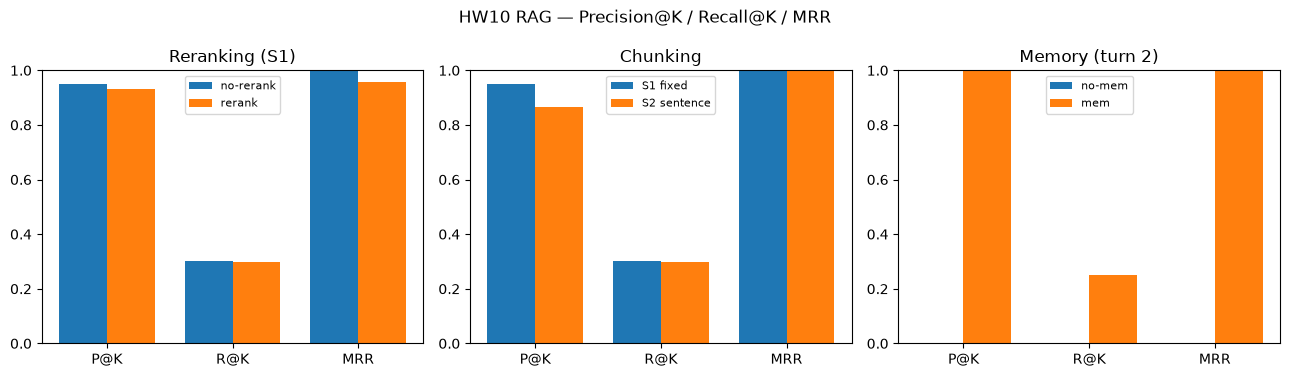

Saved -> hw10_comparison.png


In [12]:
# Bar chart of the three comparisons
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
def bars(ax, title, a, b, la, lb):
    met = ["P@K","R@K","MRR"]; x = np.arange(3); w = 0.38
    ax.bar(x-w/2, [a[m] for m in met], w, label=la)
    ax.bar(x+w/2, [b[m] for m in met], w, label=lb)
    ax.set_xticks(x); ax.set_xticklabels(met); ax.set_title(title); ax.set_ylim(0,1); ax.legend(fontsize=8)
bars(axes[0], "Reranking (S1)", no_rr, with_rr, "no-rerank", "rerank")
bars(axes[1], "Chunking", strat1, strat2, "S1 fixed", "S2 sentence")
bars(axes[2], "Memory (turn 2)", mem_off, mem_on, "no-mem", "mem")
fig.suptitle("HW10 RAG — Precision@K / Recall@K / MRR"); fig.tight_layout()
fig.savefig("hw10_comparison.png", dpi=120, bbox_inches="tight"); plt.show()
print("Saved -> hw10_comparison.png")


### Standing artifacts (Req. 0.3) — write `METRICS.md`

In [13]:
metrics = {
    "SID4": SID4, "SEED": SEED,
    "dataset": "ccdv/arxiv-summarization [document], first 100 train docs",
    "embedder": EMB_MODEL, "reranker": RERANK_MODEL, "vector_db": "ChromaDB",
    "K": K, "n_candidates": N_CANDIDATES,
    "chunks": {"S1_fixed": len(chunks_fixed), "S2_sentence": len(chunks_sent)},
    "eval_queries": len(eval_set),
    "reranking":  {"no_rerank": no_rr, "with_rerank": with_rr},
    "chunking":   {"S1_fixed": strat1, "S2_sentence": strat2},
    "memory":     {"without": mem_off, "with": mem_on},
}
with open("metrics.json", "w", encoding="utf-8") as f: json.dump(metrics, f, indent=2)

def mdrow(n,m): return f"| {n} | {m['P@K']:.3f} | {m['R@K']:.3f} | {m['MRR']:.3f} |"
lines = [
    "# METRICS - HW10 RAG (Reranking / Chunking / Conversational Memory)\n",
    f"- SID4={SID4}, SEED={SEED}",
    f"- Dataset: ccdv/arxiv-summarization [document], first {N_DOCS} docs | DB: ChromaDB",
    f"- Embedder: {EMB_MODEL} | Reranker: {RERANK_MODEL} | K={K}",
    f"- Chunks: S1 fixed={len(chunks_fixed)}, S2 sentence={len(chunks_sent)} | eval queries={len(eval_set)}\n",
    "## Reranking (Strategy 1 index)\n",
    f"| setting | P@{K} | R@{K} | MRR |", "|---|---|---|---|",
    mdrow("without reranking", no_rr), mdrow("with reranking", with_rr),
    "\n## Chunking strategy\n",
    f"| strategy | P@{K} | R@{K} | MRR |", "|---|---|---|---|",
    mdrow("S1 fixed sliding window", strat1), mdrow("S2 sentence packing", strat2),
    "\n## Conversational memory (turn-2 follow-up)\n",
    f"| setting | P@{K} | R@{K} | MRR |", "|---|---|---|---|",
    mdrow("without memory", mem_off), mdrow("with memory", mem_on),
]
with open("METRICS.md", "w", encoding="utf-8") as f: f.write("\n".join(lines) + "\n")
print("\n".join(lines)); print("\nSaved -> METRICS.md, metrics.json")


# METRICS - HW10 RAG (Reranking / Chunking / Conversational Memory)

- SID4=2708, SEED=2708
- Dataset: ccdv/arxiv-summarization [document], first 100 docs | DB: ChromaDB
- Embedder: sentence-transformers/all-MiniLM-L6-v2 | Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2 | K=5
- Chunks: S1 fixed=4094, S2 sentence=3570 | eval queries=12

## Reranking (Strategy 1 index)

| setting | P@5 | R@5 | MRR |
|---|---|---|---|
| without reranking | 0.950 | 0.301 | 1.000 |
| with reranking | 0.933 | 0.296 | 0.958 |

## Chunking strategy

| strategy | P@5 | R@5 | MRR |
|---|---|---|---|
| S1 fixed sliding window | 0.950 | 0.301 | 1.000 |
| S2 sentence packing | 0.867 | 0.300 | 1.000 |

## Conversational memory (turn-2 follow-up)

| setting | P@5 | R@5 | MRR |
|---|---|---|---|
| without memory | 0.000 | 0.000 | 0.000 |
| with memory | 1.000 | 0.250 | 1.000 |

Saved -> METRICS.md, metrics.json


## Findings & Discussion

> Fill in with your actual numbers after running.

**Without vs with reranking.** The cross-encoder reranker should raise Precision@K and MRR over the bi-encoder-only retrieval: the bi-encoder compresses the query and each chunk into independent vectors and matches by cosine, while the cross-encoder reads the query and candidate *together* and scores true relevance, so it promotes the genuinely useful chunks that the bi-encoder ranked slightly lower. The gain is largest on MRR (the first relevant hit moves up). _[State your deltas.]_

**Chunking strategy 1 vs 2.** Fixed-size sliding windows (S1) guarantee uniform size and overlap, so a relevant passage is rarely split across a boundary — good recall, but chunks can start/end mid-sentence and mix topics. Sentence-aware packing (S2) produces cleaner, self-contained chunks with no overlap, which tends to help precision but can miss content that straddles its (non-overlapping) boundaries. _[Say which won on P@K/R@K/MRR for your run and why that fits.]_

**Without vs with conversational memory.** The bare turn-2 follow-up ("what are its limitations?") has no topic, so the bi-encoder retrieves generic chunks and almost none from the intended paper. Condensing the query with the remembered turn-1 topic injects the right terms, so retrieval returns chunks from the correct document — a clear jump in Recall@K and MRR. This shows why multi-turn RAG needs query rewriting/memory: retrieval is stateless, and under-specified follow-ups fail without it.

**Overall.** Reranking and conversational memory both improve retrieval quality at low cost (rerank only re-scores a short candidate list; memory only rewrites the query), while the chunking choice trades precision against recall. _[Add one line on which change helped most on your numbers.]_


## Files produced

| File | For |
|---|---|
| `hw10_comparison.png` | P@K/R@K/MRR bar charts for the three comparisons |
| `METRICS.md`, `metrics.json` | Req. 0.3 metrics |

**Repo checklist (Req. 0.3):** executed `.ipynb`, `METRICS.md`, `RUN_LOG.txt`, `AI_USE.md` in your private repo `data266-<SID4>`, tagged **`hw10`**. Commit **incrementally**; do not commit any dataset cache.
